In [1]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

GPU: NVIDIA A100-PCIE-40GB
PyTorch: 2.11.0+cu128
CUDA: 12.8


In [2]:
import sys
print(sys.executable)

/venv/main/bin/python


In [3]:
import sys

!{sys.executable} -m pip install --upgrade --force-reinstall \
    torch==2.12.0 \
    --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
  Using cached torch-2.12.0%2Bcu130-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (31 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 7.6 MB/s  0:00:540:00:0100:02
  Using cached cuda_bindings-13.4.4-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 7.2 MB/s  0:00:510:00:0100:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.7 MB/s  0:00:220:00:0100:01
  

In [1]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

GPU: NVIDIA A100-PCIE-40GB
PyTorch: 2.12.0+cu130
CUDA: 13.0


In [3]:
import sys
!{sys.executable} -m pip install numpy pandas matplotlib tiktoken tqdm

  Using cached pandas-3.1.1-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached tiktoken-0.14.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (6.7 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached regex-2026.9.29-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp312-c

In [4]:
# Environment + reproducibility
import os, subprocess, random, math, json, time, urllib.request
from pathlib import Path
from dataclasses import dataclass, asdict

# Must be set before deterministic CUDA GEMMs are exercised.
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.use_deterministic_algorithms(True)

print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    r = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    print(r.stdout[:2500] if r.returncode == 0 else 'nvidia-smi unavailable')
print('Deterministic algorithms:', torch.are_deterministic_algorithms_enabled())


PyTorch: 2.12.0+cu130
Device: cuda
GPU: NVIDIA A100-PCIE-40GB
Thu Nov  5 05:39:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          On  |   00000000:B5:00.0 Off |                  Off |
| N/A   31C    P0             32W /  250W |       4MiB /  40960MiB |      0%      Default |
|                                         |                        |          

In [5]:
# Configuration: clean 10M Phase-3 setup
PROJECT_ID = '10m_clean_local_mixer_mechanism_test'
ROOT = Path('/workspace') if Path('/workspace').exists() else Path('.')
OUT_DIR = ROOT / PROJECT_ID
CKPT_DIR = OUT_DIR / 'results'
DATA_DIR = OUT_DIR / 'data'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

N_LAYER    = 6
N_EMBD     = 384
N_HEAD     = 6
BLOCK_SIZE = 256
DROPOUT    = 0.2

BATCH_SIZE    = 64
MAX_ITERS     = 3000
EVAL_INTERVAL = 100
EVAL_BATCHES  = 50
LEARNING_RATE = 3e-4
MIN_LR        = 3e-5
WARMUP_ITERS  = 100
WEIGHT_DECAY  = 0.1
BETA1, BETA2  = 0.9, 0.95
GRAD_CLIP     = 1.0
FIXED_VAL_SEED = 99991

BASE_SEED = 1337
FOLLOWUP_SEEDS = [42, 123]
REFERENCE_ATTNONLY_SEED1337 = 1.579988667964935
REFERENCE_FFNONLY_MEAN = 3.350

print('Output:', OUT_DIR)
print('Reference AttnOnly seed-1337 best val:', REFERENCE_ATTNONLY_SEED1337)


Output: /workspace/10m_clean_local_mixer_mechanism_test
Reference AttnOnly seed-1337 best val: 1.579988667964935


In [6]:
# Cell 3 - Dataset (TinyShakespeare, character-level — identical to original)
import urllib.request

DATA_DIR = OUT_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)
txt_path = DATA_DIR / 'input.txt'

if not txt_path.exists():
    print('Downloading TinyShakespeare...')
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt',
        txt_path
    )
text = txt_path.read_text()

chars = sorted(set(text))
VOCAB_SIZE = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data   = data[n:]

print(f'Vocab size: {VOCAB_SIZE}')
print(f'Train tokens: {len(train_data):,}')
print(f'Val tokens:   {len(val_data):,}')


Vocab size: 65
Train tokens: 1,003,854
Val tokens:   111,540


In [7]:
# Cell 4 - Batcher with FIXED validation batches (critical architecture detail)
#
# This is the single most important fix from the original nanoGPT pilot:
# random val batches at every eval introduce noise that masks slow learners
# like AttnOnly. Fixed batches (seed 99,991) ensure identical evaluation
# data across every step and every seed, so seed-to-seed variance reflects
# the model, not the evaluation sample.

class SequenceBatcher:
    def __init__(self, train_data, val_data, block_size, batch_size, device,
                 fixed_val_seed=FIXED_VAL_SEED, n_fixed_val_batches=50):
        self.train_data = train_data
        self.val_data   = val_data
        self.block_size = block_size
        self.batch_size = batch_size
        self.device     = device

        # Build fixed val batches ONCE, using an isolated generator so it
        # never interacts with the global / per-experiment seed state.
        g = torch.Generator().manual_seed(fixed_val_seed)
        self.fixed_val_batches = []
        for _ in range(n_fixed_val_batches):
            ix = torch.randint(len(val_data) - block_size, (batch_size,), generator=g)
            xb = torch.stack([val_data[i:i+block_size]     for i in ix]).to(device)
            yb = torch.stack([val_data[i+1:i+block_size+1] for i in ix]).to(device)
            self.fixed_val_batches.append((xb, yb))

    def sample(self, split):
        d = self.train_data if split == 'train' else self.val_data
        ix = torch.randint(len(d) - self.block_size, (self.batch_size,))
        xb = torch.stack([d[i:i+self.block_size]     for i in ix]).to(self.device)
        yb = torch.stack([d[i+1:i+self.block_size+1] for i in ix]).to(self.device)
        return xb, yb

# Build ONCE — shared across all seeds in this notebook, exactly as in
# the original ResidualGPT run, so every config sees identical val data.
BATCHER = SequenceBatcher(train_data, val_data, BLOCK_SIZE, BATCH_SIZE, DEVICE)
print(f'Fixed val batches built: {len(BATCHER.fixed_val_batches)} batches, seed=99991')


Fixed val batches built: 50 batches, seed=99991


In [8]:
# Cell 5 - ResidualGPT model
# Critical correctness requirements baked in here:
#   (a) NO runtime gain multiplier in forward() — gain is applied to WEIGHTS
#       at init time only, via apply_output_gains(), never as a forward-pass
#       multiplier. (That bug was caught and fixed in the original project —
#       see paper Section 5.1.)
#   (b) Weight tying between token_embed and lm_head.
#   (c) attention_skip / mlp_skip flags control residual connections.

@dataclass
class ResidualSwitch:
    use_attention_skip: bool = True
    use_mlp_skip:       bool = True
    attention_gain:     float = 1.0
    mlp_gain:           float = 1.0


class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        assert N_EMBD % N_HEAD == 0
        self.qkv  = nn.Linear(N_EMBD, 3 * N_EMBD, bias=False)
        self.out  = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)
        self.n_head = N_HEAD
        self.head_dim = N_EMBD // N_HEAD

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.drop.p if self.training else 0.0, is_causal=True
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.out(y))


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1  = nn.Linear(N_EMBD, 4 * N_EMBD, bias=False)
        self.fc2  = nn.Linear(4 * N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))


class Block(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch    = switch
        self.ln1       = nn.LayerNorm(N_EMBD)
        self.ln2       = nn.LayerNorm(N_EMBD)
        self.attn      = CausalSelfAttention()
        self.mlp       = MLP()

    def forward(self, x):
        # NO runtime multiplier here. Gain is purely a weight-init-time effect.
        a = self.attn(self.ln1(x))
        x = x + a if self.switch.use_attention_skip else a
        m = self.mlp(self.ln2(x))
        x = x + m if self.switch.use_mlp_skip else m
        return x


class ResidualGPT(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.token_embed = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.pos_embed   = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.drop        = nn.Dropout(DROPOUT)
        self.blocks      = nn.ModuleList([Block(switch) for _ in range(N_LAYER)])
        self.ln_f        = nn.LayerNorm(N_EMBD)
        self.lm_head     = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)

        # Weight tying
        self.lm_head.weight = self.token_embed.weight

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def apply_output_gains(self):
        """Weight-level gain application, called ONCE before optimizer construction.
        With gain=1.0 (this run's config) this is a no-op, included only for
        architectural parity with the original implementation."""
        if self.switch.mlp_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.mlp.fc2.weight.mul_(self.switch.mlp_gain)
        if self.switch.attention_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.attn.out.weight.mul_(self.switch.attention_gain)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embed(idx) + self.pos_embed(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def param_count(self):
        return sum(p.numel() for p in self.parameters())

print('Model class defined')


Model class defined


In [9]:
class LocalMixer(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(N_EMBD, 2 * N_EMBD, bias=False)
        self.fc2 = nn.Linear(2 * N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        # x: (B,T,D); nn.Linear acts independently at each token position.
        return self.drop(self.fc2(F.gelu(self.fc1(x))))


class LocalMixerBlock(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.ln1 = nn.LayerNorm(N_EMBD)
        self.ln2 = nn.LayerNorm(N_EMBD)
        self.mixer = LocalMixer()
        self.mlp = MLP()

    def forward(self, x):
        a = self.mixer(self.ln1(x))
        x = x + a if self.switch.use_attention_skip else a
        m = self.mlp(self.ln2(x))
        x = x + m if self.switch.use_mlp_skip else m
        return x


class LocalMixerGPT(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.token_embed = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.pos_embed = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.drop = nn.Dropout(DROPOUT)
        self.blocks = nn.ModuleList([LocalMixerBlock(switch) for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.lm_head = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)
        self.lm_head.weight = self.token_embed.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def apply_output_gains(self):
        if self.switch.mlp_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.mlp.fc2.weight.mul_(self.switch.mlp_gain)
        if self.switch.attention_gain != 1.0:
            # In the intervention, attention_gain maps to the output projection
            # of the replacement mixer. Gain=1.0 in this experiment.
            with torch.no_grad():
                for block in self.blocks:
                    block.mixer.fc2.weight.mul_(self.switch.attention_gain)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embed(idx) + self.pos_embed(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def param_count(self):
        return sum(p.numel() for p in self.parameters())

attn_params = sum(p.numel() for p in CausalSelfAttention().parameters())
mixer_params = sum(p.numel() for p in LocalMixer().parameters())
print(f'Attention params: {attn_params:,}')
print(f'LocalMixer params: {mixer_params:,}')
assert attn_params == mixer_params, 'Parameter budgets do not match.'
print('PASS: attention and LocalMixer parameter counts match exactly.')


Attention params: 589,824
LocalMixer params: 589,824
PASS: attention and LocalMixer parameter counts match exactly.


In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == 'cuda':
        torch.cuda.manual_seed_all(seed)


def learning_rate_at(step, max_iters=MAX_ITERS, base_lr=LEARNING_RATE,
                     min_lr=MIN_LR, warmup_iters=WARMUP_ITERS):
    if step < warmup_iters:
        return base_lr * (step + 1) / max(1, warmup_iters)
    if step >= max_iters:
        return min_lr
    progress = (step - warmup_iters) / max(1, max_iters - warmup_iters)
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return min_lr + cosine * (base_lr - min_lr)


@torch.no_grad()
def estimate_val_loss(model, n_batches=EVAL_BATCHES):
    model.eval()
    losses = []
    for xb, yb in BATCHER.fixed_val_batches[:n_batches]:
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))


@torch.no_grad()
def estimate_train_loss(model, n_batches=EVAL_BATCHES):
    model.eval()
    losses = []
    for _ in range(n_batches):
        xb, yb = BATCHER.sample('train')
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))


def make_optimizer(model):
    decay, no_decay = [], []
    for _, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.ndim >= 2 else no_decay).append(p)
    return torch.optim.AdamW(
        [{'params': decay, 'weight_decay': WEIGHT_DECAY},
         {'params': no_decay, 'weight_decay': 0.0}],
        lr=LEARNING_RATE, betas=(BETA1, BETA2)
    )


def result_path(condition, seed):
    return CKPT_DIR / f'{condition}_seed{seed}.json'


def save_result(result):
    path = result_path(result['condition'], result['seed'])
    with open(path, 'w') as f:
        json.dump(result, f, indent=2)
    print('Saved:', path)


def load_result(condition, seed):
    path = result_path(condition, seed)
    if path.exists():
        with open(path) as f:
            return json.load(f)
    return None


def train_one_run(condition, seed, model_cls, switch, max_iters=MAX_ITERS,
                  eval_interval=EVAL_INTERVAL, eval_batches=EVAL_BATCHES, verbose=True):
    set_seed(seed)
    model = model_cls(switch).to(DEVICE)
    model.apply_output_gains()
    optimizer = make_optimizer(model)

    history, best_val, best_step = [], float('inf'), -1
    started = time.time()

    val0 = estimate_val_loss(model, eval_batches)
    train0 = estimate_train_loss(model, eval_batches)
    history.append({'step': 0, 'lr': learning_rate_at(0, max_iters),
                    'train_loss': train0, 'val_loss': val0})
    best_val, best_step = val0, 0

    for step in range(1, max_iters + 1):
        lr = learning_rate_at(step, max_iters)
        for g in optimizer.param_groups:
            g['lr'] = lr

        optimizer.zero_grad(set_to_none=True)
        xb, yb = BATCHER.sample('train')
        _, loss = model(xb, yb)
        loss.backward()
        if GRAD_CLIP is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        if step % eval_interval == 0 or step == max_iters:
            val_loss = estimate_val_loss(model, eval_batches)
            train_loss = estimate_train_loss(model, eval_batches)
            if val_loss < best_val:
                best_val, best_step = val_loss, step
            history.append({'step': step, 'lr': lr,
                            'train_loss': train_loss, 'val_loss': val_loss})
            if verbose:
                print(f'{condition:16s} seed={seed} step={step:4d} '
                      f'lr={lr:.2e} train={train_loss:.4f} val={val_loss:.4f} '
                      f'best={best_val:.4f}@{best_step} elapsed={time.time()-started:.0f}s')

    return {
        'condition': condition,
        'seed': seed,
        'model_class': model_cls.__name__,
        'switch': asdict(switch),
        'best_step': best_step,
        'best_val_loss': best_val,
        'best_val_ppl': math.exp(min(best_val, 20)),
        'final_val_loss': history[-1]['val_loss'],
        'final_train_loss': history[-1]['train_loss'],
        'param_count': model.param_count(),
        'history': history,
    }


In [ ]:
# Experimental conditions
ATTN_ONLY = ResidualSwitch(True, False, 1.0, 1.0)
# FFN_ONLY  = ResidualSwitch(False, True, 1.0, 1.0)
# LOCAL_MIXER_ONLY = ResidualSwitch(True, False, 1.0, 1.0)

CONDITIONS = {
    'AttnOnly':       (ResidualGPT,   ATTN_ONLY),
    'LocalMixerOnly': (LocalMixerGPT, LOCAL_MIXER_ONLY),
    'FFNOnly':        (ResidualGPT,   FFN_ONLY),
}

for name, (cls, sw) in CONDITIONS.items():
    set_seed(BASE_SEED)
    m = cls(sw)
    print(f'{name:16s} params={m.param_count():,}')
    del m


In [11]:
# Positive-control condition: AttnOnly only
ATTN_ONLY = ResidualSwitch(True, False, 1.0, 1.0)

CONDITIONS = {
    'AttnOnly': (ResidualGPT, ATTN_ONLY),
}

for name, (cls, sw) in CONDITIONS.items():
    set_seed(BASE_SEED)
    m = cls(sw)
    print(f'{name:16s} params={m.param_count():,}')
    del m

AttnOnly         params=10,750,080


In [18]:
LOCAL_MIXER_ONLY = ResidualSwitch(True, False, 1.0, 1.0)

CONDITIONS = {
    'LocalMixerOnly': (LocalMixerGPT, LOCAL_MIXER_ONLY),
}

for name, (cls, sw) in CONDITIONS.items():
    set_seed(BASE_SEED)
    m = cls(sw)
    print(f'{name:16s} params={m.param_count():,}')
    del m

LocalMixerOnly   params=10,750,080


In [19]:
print("=" * 72)
print("FULL RUN: LocalMixerOnly seed=1337")
print("=" * 72)

local_mixer_1337 = train_one_run(
    condition='LocalMixerOnly',
    seed=1337,
    model_cls=LocalMixerGPT,
    switch=LOCAL_MIXER_ONLY,
    max_iters=3000,
    eval_interval=100,
    eval_batches=EVAL_BATCHES,
    verbose=True
)

local_mixer_1337

FULL RUN: LocalMixerOnly seed=1337
LocalMixerOnly   seed=1337 step= 100 lr=3.00e-04 train=2.5375 val=2.5403 best=2.5403@100 elapsed=5s
LocalMixerOnly   seed=1337 step= 200 lr=2.99e-04 train=2.4926 val=2.5056 best=2.5056@200 elapsed=9s
LocalMixerOnly   seed=1337 step= 300 lr=2.97e-04 train=2.4843 val=2.5075 best=2.5056@200 elapsed=12s
LocalMixerOnly   seed=1337 step= 400 lr=2.93e-04 train=2.4821 val=2.5059 best=2.5056@200 elapsed=16s
LocalMixerOnly   seed=1337 step= 500 lr=2.88e-04 train=2.4723 val=2.4948 best=2.4948@500 elapsed=20s
LocalMixerOnly   seed=1337 step= 600 lr=2.81e-04 train=2.4710 val=2.5011 best=2.4948@500 elapsed=24s
LocalMixerOnly   seed=1337 step= 700 lr=2.72e-04 train=2.4703 val=2.5049 best=2.4948@500 elapsed=28s
LocalMixerOnly   seed=1337 step= 800 lr=2.63e-04 train=2.4677 val=2.5006 best=2.4948@500 elapsed=32s
LocalMixerOnly   seed=1337 step= 900 lr=2.52e-04 train=2.4690 val=2.4962 best=2.4948@500 elapsed=35s
LocalMixerOnly   seed=1337 step=1000 lr=2.41e-04 train=2.4

{'condition': 'LocalMixerOnly',
 'seed': 1337,
 'model_class': 'LocalMixerGPT',
 'switch': {'use_attention_skip': True,
  'use_mlp_skip': False,
  'attention_gain': 1.0,
  'mlp_gain': 1.0},
 'best_step': 2900,
 'best_val_loss': 2.490946664810181,
 'best_val_ppl': 12.072699512322256,
 'final_val_loss': 2.4932315826416014,
 'final_train_loss': 2.4614654111862184,
 'param_count': 10750080,
 'history': [{'step': 0,
   'lr': 2.9999999999999997e-06,
   'train_loss': 4.226069612503052,
   'val_loss': 4.228981447219849},
  {'step': 100,
   'lr': 0.0003,
   'train_loss': 2.5375495290756227,
   'val_loss': 2.5403393745422362},
  {'step': 200,
   'lr': 0.0002992086242158385,
   'train_loss': 2.4926310682296755,
   'val_loss': 2.5056341886520386},
  {'step': 300,
   'lr': 0.00029684377502086165,
   'train_loss': 2.4843239641189574,
   'val_loss': 2.5075377893447874},
  {'step': 400,
   'lr': 0.0002929331781096783,
   'train_loss': 2.4821052598953246,
   'val_loss': 2.505866222381592},
  {'step': 5

In [12]:
SANITY_STEPS = 300
sanity = {}
for condition, (model_cls, switch) in CONDITIONS.items():
    print()
    print('='*72)
    print('SANITY:', condition)
    print('='*72)
    sanity[condition] = train_one_run(
        condition, BASE_SEED, model_cls, switch,
        max_iters=SANITY_STEPS, eval_interval=100, eval_batches=EVAL_BATCHES
    )

pd.DataFrame([
    {'condition': k, 'step300_val': v['final_val_loss'], 'best_val': v['best_val_loss']}
    for k, v in sanity.items()
]).sort_values('step300_val')



SANITY: AttnOnly
AttnOnly         seed=1337 step= 100 lr=3.00e-04 train=2.5337 val=2.5281 best=2.5281@100 elapsed=6s
AttnOnly         seed=1337 step= 200 lr=1.65e-04 train=2.4311 val=2.4369 best=2.4369@200 elapsed=10s
AttnOnly         seed=1337 step= 300 lr=3.00e-05 train=2.3906 val=2.4043 best=2.4043@300 elapsed=14s


,condition,step300_val,best_val
0,AttnOnly,2.404349,2.404349


In [13]:
results = {}
for condition, (model_cls, switch) in CONDITIONS.items():
    existing = load_result(condition, BASE_SEED)
    if existing is not None:
        print(f'Skipping {condition} seed={BASE_SEED}; existing best={existing["best_val_loss"]:.6f}')
        results[(condition, BASE_SEED)] = existing
        continue

    print()
    print('='*72)
    print(f'FULL RUN: {condition} seed={BASE_SEED}')
    print('='*72)
    result = train_one_run(condition, BASE_SEED, model_cls, switch)
    save_result(result)
    results[(condition, BASE_SEED)] = result

summary1337 = pd.DataFrame([
    {'condition': c, 'seed': s, 'best_val_loss': r['best_val_loss'],
     'best_step': r['best_step'], 'final_val_loss': r['final_val_loss'],
     'params': r['param_count']}
    for (c, s), r in results.items() if s == BASE_SEED
]).sort_values('best_val_loss')
summary1337



FULL RUN: AttnOnly seed=1337
AttnOnly         seed=1337 step= 100 lr=3.00e-04 train=2.5337 val=2.5281 best=2.5281@100 elapsed=5s
AttnOnly         seed=1337 step= 200 lr=2.99e-04 train=2.4331 val=2.4356 best=2.4356@200 elapsed=9s
AttnOnly         seed=1337 step= 300 lr=2.97e-04 train=2.3116 val=2.3422 best=2.3422@300 elapsed=14s
AttnOnly         seed=1337 step= 400 lr=2.93e-04 train=2.2001 val=2.2409 best=2.2409@400 elapsed=18s
AttnOnly         seed=1337 step= 500 lr=2.88e-04 train=2.0909 val=2.1616 best=2.1616@500 elapsed=22s
AttnOnly         seed=1337 step= 600 lr=2.81e-04 train=1.9724 val=2.0789 best=2.0789@600 elapsed=26s
AttnOnly         seed=1337 step= 700 lr=2.72e-04 train=1.8793 val=2.0155 best=2.0155@700 elapsed=31s
AttnOnly         seed=1337 step= 800 lr=2.63e-04 train=1.8228 val=1.9894 best=1.9894@800 elapsed=35s
AttnOnly         seed=1337 step= 900 lr=2.52e-04 train=1.7638 val=1.9330 best=1.9330@900 elapsed=39s
AttnOnly         seed=1337 step=1000 lr=2.41e-04 train=1.6986 v

,condition,seed,best_val_loss,best_step,final_val_loss,params
0,AttnOnly,1337,1.60845,3000,1.60845,10750080


In [20]:
LOCAL_MIXER_ONLY = ResidualSwitch(True, False, 1.0, 1.0)

CONDITIONS = {
    'LocalMixerOnly': (LocalMixerGPT, LOCAL_MIXER_ONLY),
}

for name, (cls, sw) in CONDITIONS.items():
    set_seed(BASE_SEED)
    m = cls(sw)
    print(f'{name:16s} params={m.param_count():,}')
    del m

LocalMixerOnly   params=10,750,080


In [21]:
print("=" * 72)
print("FULL RUN: LocalMixerOnly seed=1337")
print("=" * 72)

local_mixer_1337 = train_one_run(
    condition='LocalMixerOnly',
    seed=1337,
    model_cls=LocalMixerGPT,
    switch=LOCAL_MIXER_ONLY,
    max_iters=3000,
    eval_interval=100,
    eval_batches=EVAL_BATCHES,
    verbose=True
)

print("Best val:", local_mixer_1337['best_val_loss'])
print("Best step:", local_mixer_1337['best_step'])
print("Final val:", local_mixer_1337['final_val_loss'])

FULL RUN: LocalMixerOnly seed=1337
LocalMixerOnly   seed=1337 step= 100 lr=3.00e-04 train=2.5375 val=2.5403 best=2.5403@100 elapsed=5s
LocalMixerOnly   seed=1337 step= 200 lr=2.99e-04 train=2.4926 val=2.5056 best=2.5056@200 elapsed=8s
LocalMixerOnly   seed=1337 step= 300 lr=2.97e-04 train=2.4843 val=2.5075 best=2.5056@200 elapsed=12s
LocalMixerOnly   seed=1337 step= 400 lr=2.93e-04 train=2.4821 val=2.5059 best=2.5056@200 elapsed=16s
LocalMixerOnly   seed=1337 step= 500 lr=2.88e-04 train=2.4723 val=2.4948 best=2.4948@500 elapsed=20s
LocalMixerOnly   seed=1337 step= 600 lr=2.81e-04 train=2.4710 val=2.5011 best=2.4948@500 elapsed=23s
LocalMixerOnly   seed=1337 step= 700 lr=2.72e-04 train=2.4703 val=2.5049 best=2.4948@500 elapsed=27s
LocalMixerOnly   seed=1337 step= 800 lr=2.63e-04 train=2.4677 val=2.5006 best=2.4948@500 elapsed=31s
LocalMixerOnly   seed=1337 step= 900 lr=2.52e-04 train=2.4690 val=2.4962 best=2.4948@500 elapsed=35s
LocalMixerOnly   seed=1337 step=1000 lr=2.41e-04 train=2.4

In [22]:
FFN_ONLY = ResidualSwitch(False, True, 1.0, 1.0)

CONDITIONS = {
    'FFNOnly': (ResidualGPT, FFN_ONLY),
}

for name, (cls, sw) in CONDITIONS.items():
    set_seed(BASE_SEED)
    m = cls(sw)
    print(f'{name:16s} params={m.param_count():,}')
    del m

FFNOnly          params=10,750,080


In [23]:
ffn_1337 = train_one_run(
    condition='FFNOnly',
    seed=1337,
    model_cls=ResidualGPT,
    switch=FFN_ONLY,
    max_iters=3000,
    eval_interval=100,
    eval_batches=EVAL_BATCHES,
    verbose=True
)

print("Best val:", ffn_1337['best_val_loss'])
print("Best step:", ffn_1337['best_step'])
print("Final val:", ffn_1337['final_val_loss'])

FFNOnly          seed=1337 step= 100 lr=3.00e-04 train=3.3188 val=3.3597 best=3.3597@100 elapsed=5s
FFNOnly          seed=1337 step= 200 lr=2.99e-04 train=3.3145 val=3.3495 best=3.3495@200 elapsed=10s
FFNOnly          seed=1337 step= 300 lr=2.97e-04 train=3.3174 val=3.3535 best=3.3495@200 elapsed=14s
FFNOnly          seed=1337 step= 400 lr=2.93e-04 train=3.3154 val=3.3566 best=3.3495@200 elapsed=18s
FFNOnly          seed=1337 step= 500 lr=2.88e-04 train=3.3097 val=3.3512 best=3.3495@200 elapsed=22s
FFNOnly          seed=1337 step= 600 lr=2.81e-04 train=3.3125 val=3.3566 best=3.3495@200 elapsed=26s
FFNOnly          seed=1337 step= 700 lr=2.72e-04 train=3.3128 val=3.3549 best=3.3495@200 elapsed=31s
FFNOnly          seed=1337 step= 800 lr=2.63e-04 train=3.3114 val=3.3519 best=3.3495@200 elapsed=35s
FFNOnly          seed=1337 step= 900 lr=2.52e-04 train=3.3163 val=3.3537 best=3.3495@200 elapsed=39s
FFNOnly          seed=1337 step=1000 lr=2.41e-04 train=3.3137 val=3.3554 best=3.3495@200 ela

In [24]:
for seed in [42, 123]:
    result = train_one_run(
        condition='LocalMixerOnly',
        seed=seed,
        model_cls=LocalMixerGPT,
        switch=LOCAL_MIXER_ONLY,
        max_iters=3000,
        eval_interval=100,
        eval_batches=EVAL_BATCHES,
        verbose=True
    )

    print(
        seed,
        result['best_val_loss'],
        result['best_step'],
        result['final_val_loss']
    )

LocalMixerOnly   seed=42 step= 100 lr=3.00e-04 train=2.5313 val=2.5350 best=2.5350@100 elapsed=5s
LocalMixerOnly   seed=42 step= 200 lr=2.99e-04 train=2.4915 val=2.5122 best=2.5122@200 elapsed=8s
LocalMixerOnly   seed=42 step= 300 lr=2.97e-04 train=2.4826 val=2.5025 best=2.5025@300 elapsed=12s
LocalMixerOnly   seed=42 step= 400 lr=2.93e-04 train=2.4777 val=2.4977 best=2.4977@400 elapsed=16s
LocalMixerOnly   seed=42 step= 500 lr=2.88e-04 train=2.4756 val=2.4993 best=2.4977@400 elapsed=20s
LocalMixerOnly   seed=42 step= 600 lr=2.81e-04 train=2.4754 val=2.4965 best=2.4965@600 elapsed=24s
LocalMixerOnly   seed=42 step= 700 lr=2.72e-04 train=2.4714 val=2.4930 best=2.4930@700 elapsed=27s
LocalMixerOnly   seed=42 step= 800 lr=2.63e-04 train=2.4697 val=2.4976 best=2.4930@700 elapsed=31s
LocalMixerOnly   seed=42 step= 900 lr=2.52e-04 train=2.4699 val=2.5050 best=2.4930@700 elapsed=35s
LocalMixerOnly   seed=42 step=1000 lr=2.41e-04 train=2.4686 val=2.4903 best=2.4903@1000 elapsed=39s
LocalMixerO

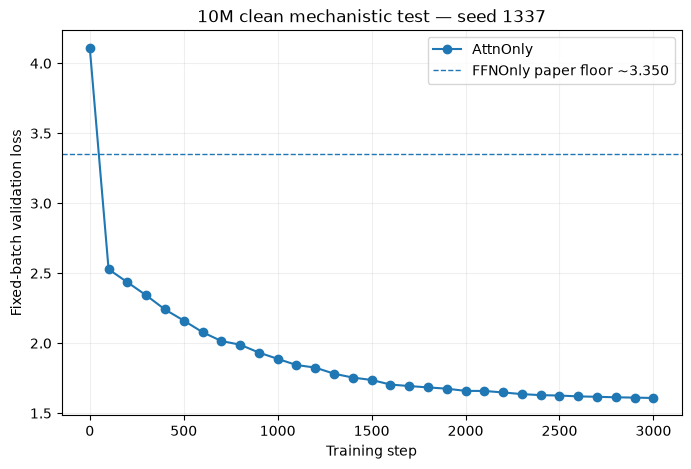

In [14]:
# Plot seed-1337 validation trajectories
plt.figure(figsize=(8, 5))
for (condition, seed), r in results.items():
    if seed != BASE_SEED:
        continue
    steps = [x['step'] for x in r['history']]
    vals = [x['val_loss'] for x in r['history']]
    plt.plot(steps, vals, marker='o', label=condition)
plt.axhline(REFERENCE_FFNONLY_MEAN, linestyle='--', linewidth=1, label='FFNOnly paper floor ~3.350')
plt.xlabel('Training step')
plt.ylabel('Fixed-batch validation loss')
plt.title('10M clean mechanistic test — seed 1337')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [15]:
FOLLOWUP_CONDITIONS = ['AttnOnly', 'LocalMixerOnly', 'FFNOnly']

for seed in FOLLOWUP_SEEDS:
    for condition in FOLLOWUP_CONDITIONS:
        model_cls, switch = CONDITIONS[condition]
        existing = load_result(condition, seed)
        if existing is not None:
            print(f'Skipping {condition} seed={seed}; existing best={existing["best_val_loss"]:.6f}')
            results[(condition, seed)] = existing
            continue
        print()
        print('='*72)
        print(f'FOLLOW-UP: {condition} seed={seed}')
        print('='*72)
        r = train_one_run(condition, seed, model_cls, switch)
        save_result(r)
        results[(condition, seed)] = r



FOLLOW-UP: AttnOnly seed=42
AttnOnly         seed=42 step= 100 lr=3.00e-04 train=2.5227 val=2.5199 best=2.5199@100 elapsed=5s
AttnOnly         seed=42 step= 200 lr=2.99e-04 train=2.4261 val=2.4455 best=2.4455@200 elapsed=9s
AttnOnly         seed=42 step= 300 lr=2.97e-04 train=2.3103 val=2.3337 best=2.3337@300 elapsed=13s
AttnOnly         seed=42 step= 400 lr=2.93e-04 train=2.1952 val=2.2340 best=2.2340@400 elapsed=18s
AttnOnly         seed=42 step= 500 lr=2.88e-04 train=2.0825 val=2.1475 best=2.1475@500 elapsed=22s
AttnOnly         seed=42 step= 600 lr=2.81e-04 train=1.9798 val=2.0723 best=2.0723@600 elapsed=26s
AttnOnly         seed=42 step= 700 lr=2.72e-04 train=1.8796 val=2.0158 best=2.0158@700 elapsed=31s
AttnOnly         seed=42 step= 800 lr=2.63e-04 train=1.8082 val=1.9683 best=1.9683@800 elapsed=35s
AttnOnly         seed=42 step= 900 lr=2.52e-04 train=1.7371 val=1.9129 best=1.9129@900 elapsed=39s
AttnOnly         seed=42 step=1000 lr=2.41e-04 train=1.6858 val=1.8801 best=1.8801

KeyError: 'LocalMixerOnly'

In [ ]:
# Aggregate all saved results, including runs from previous notebook sessions.
rows = []
for condition in CONDITIONS:
    for seed in [BASE_SEED] + FOLLOWUP_SEEDS:
        r = load_result(condition, seed)
        if r is not None:
            rows.append({
                'condition': condition,
                'seed': seed,
                'best_val_loss': r['best_val_loss'],
                'best_step': r['best_step'],
                'final_val_loss': r['final_val_loss'],
                'param_count': r['param_count'],
            })

all_runs = pd.DataFrame(rows)
display(all_runs.sort_values(['condition', 'seed']))

if len(all_runs):
    stats = all_runs.groupby('condition')['best_val_loss'].agg(['count','mean','std','min','max'])
    display(stats)
    all_runs.to_csv(OUT_DIR / 'mechanism_test_runs.csv', index=False)
    stats.to_csv(OUT_DIR / 'mechanism_test_summary.csv')
    print('Saved CSV summaries to', OUT_DIR)


In [16]:
# ============================================================
# LOCAL MIXER MECHANISM TEST — SEED 1337
# ============================================================

print("=" * 72)
print("MECHANISM TEST: LocalMixerOnly seed=1337")
print("=" * 72)

local_mixer_1337 = run_experiment(
    condition_name="LocalMixerOnly",
    residual_switch=LOCAL_MIXER_ONLY,
    seed=1337,
    max_iters=3000,
    use_local_mixer=True,
)

local_mixer_1337

MECHANISM TEST: LocalMixerOnly seed=1337


NameError: name 'run_experiment' is not defined

In [25]:
import os

RESULT_DIR = "/workspace/10m_clean_local_mixer_mechanism_test/results"

for f in sorted(os.listdir(RESULT_DIR)):
    print(f)

AttnOnly_seed1337.json
AttnOnly_seed42.json


In [26]:
save_result(local_mixer_1337)

Saved: /workspace/10m_clean_local_mixer_mechanism_test/results/LocalMixerOnly_seed1337.json


In [27]:
print(result['condition'])
print(result['seed'])
print(result['best_val_loss'])

LocalMixerOnly
123
2.490378985404968


In [28]:
save_result(result)

Saved: /workspace/10m_clean_local_mixer_mechanism_test/results/LocalMixerOnly_seed123.json


In [29]:
%whos

Variable                      Type               Data/Info
----------------------------------------------------------
ATTN_ONLY                     ResidualSwitch     ResidualSwitch(use_attent<...>n_gain=1.0, mlp_gain=1.0)
BASE_SEED                     int                1337
BATCHER                       SequenceBatcher    <__main__.SequenceBatcher<...>object at 0x7f73d4ae4ef0>
BATCH_SIZE                    int                64
BETA1                         float              0.9
BETA2                         float              0.95
BLOCK_SIZE                    int                256
Block                         type               <class '__main__.Block'>
CKPT_DIR                      PosixPath          /workspace/10m_clean_loca<...>er_mechanism_test/results
CONDITIONS                    dict               n=1
CausalSelfAttention           type               <class '__main__.CausalSelfAttention'>
DATA_DIR                      PosixPath          /workspace/10m_clean_loca<...>mixer_m

In [30]:
save_result(ffn_1337)

Saved: /workspace/10m_clean_local_mixer_mechanism_test/results/FFNOnly_seed1337.json


In [31]:
local_mixer_42 = train_one_run(
    condition='LocalMixerOnly',
    seed=42,
    model_cls=LocalMixerGPT,
    switch=LOCAL_MIXER_ONLY,
    max_iters=3000,
    eval_interval=100,
    eval_batches=EVAL_BATCHES,
    verbose=True
)

save_result(local_mixer_42)

LocalMixerOnly   seed=42 step= 100 lr=3.00e-04 train=2.5313 val=2.5350 best=2.5350@100 elapsed=4s
LocalMixerOnly   seed=42 step= 200 lr=2.99e-04 train=2.4915 val=2.5122 best=2.5122@200 elapsed=8s
LocalMixerOnly   seed=42 step= 300 lr=2.97e-04 train=2.4826 val=2.5025 best=2.5025@300 elapsed=12s
LocalMixerOnly   seed=42 step= 400 lr=2.93e-04 train=2.4777 val=2.4977 best=2.4977@400 elapsed=16s
LocalMixerOnly   seed=42 step= 500 lr=2.88e-04 train=2.4756 val=2.4993 best=2.4977@400 elapsed=20s
LocalMixerOnly   seed=42 step= 600 lr=2.81e-04 train=2.4754 val=2.4965 best=2.4965@600 elapsed=23s
LocalMixerOnly   seed=42 step= 700 lr=2.72e-04 train=2.4714 val=2.4930 best=2.4930@700 elapsed=27s
LocalMixerOnly   seed=42 step= 800 lr=2.63e-04 train=2.4697 val=2.4976 best=2.4930@700 elapsed=31s
LocalMixerOnly   seed=42 step= 900 lr=2.52e-04 train=2.4699 val=2.5050 best=2.4930@700 elapsed=35s
LocalMixerOnly   seed=42 step=1000 lr=2.41e-04 train=2.4686 val=2.4903 best=2.4903@1000 elapsed=39s
LocalMixerO

In [32]:
import os

RESULT_DIR = "/workspace/10m_clean_local_mixer_mechanism_test/results"

for f in sorted(os.listdir(RESULT_DIR)):
    print(f)

AttnOnly_seed1337.json
AttnOnly_seed42.json
FFNOnly_seed1337.json
LocalMixerOnly_seed123.json
LocalMixerOnly_seed1337.json
LocalMixerOnly_seed42.json
